# Load hugging face tweeteval dataset

In [1]:
# Install Hugging Face datasets library
!pip install -q datasets

# Import the library
from datasets import load_dataset

# Load the sentiment subset
tweet_dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

print("TweetEval sentiment dataset loaded successfully!")

README.md:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

sentiment/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.78MB            

sentiment/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  901kB            

sentiment/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

sentiment/validation-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  167kB            

sentiment/validation-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/45615 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/12284 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

TweetEval sentiment dataset loaded successfully!


In [2]:
# Check the size of the split
print("Training reviews:", len(tweet_dataset["train"]))
print("Validation reviews:", len(tweet_dataset["validation"]))
print("Testing reviews:", len(tweet_dataset["test"]))

# Check the label mapping
print("\nLabel mapping:")
print(tweet_dataset["train"].features["label"])

# Display sample tweets
print("\nSample tweets:")

for i in range(5):
    row = tweet_dataset["train"][i]

    print("\nTweet:", row["text"])
    print("Sentiment:", row["label"])

Training reviews: 45615
Validation reviews: 2000
Testing reviews: 12284

Label mapping:
ClassLabel(names=['negative', 'neutral', 'positive'])

Sample tweets:

Tweet: "QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"
Sentiment: 2

Tweet: "Ben Smith / Smith (concussion) remains out of the lineup Thursday, Curtis #NHL #SJ"
Sentiment: 1

Tweet: Sorry bout the stream last night I crashed out but will be on tonight for sure. Then back to Minecraft in pc tomorrow night.
Sentiment: 1

Tweet: Chase Headley's RBI double in the 8th inning off David Price snapped a Yankees streak of 33 consecutive scoreless innings against Blue Jays
Sentiment: 1

Tweet: @user Alciato: Bee will invest 150 million in January, another 200 in the Summer and plans to bring Messi by 2017"
Sentiment: 2


## Examine the class distribution

TRAINING SENTIMENT DISTRIBUTION
Neutral     20673
Positive    17849
Negative     7093
Name: count, dtype: int64

TRAINING SENTIMENT PERCENTAGES
Neutral     45.32
Positive    39.13
Negative    15.55
Name: proportion, dtype: float64


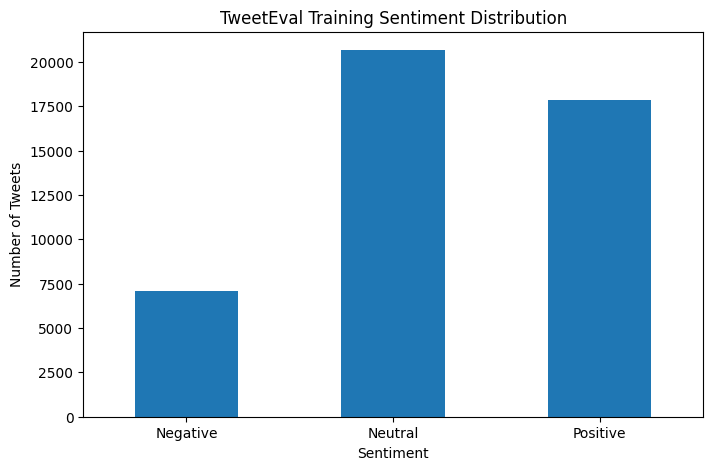

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

sentiment_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

# Examine training distribution
tweet_train_labels = pd.Series(
    tweet_dataset["train"]["label"]
).map(sentiment_names)

print("TRAINING SENTIMENT DISTRIBUTION")
print(tweet_train_labels.value_counts())

print("\nTRAINING SENTIMENT PERCENTAGES")
print(
    (tweet_train_labels.value_counts(normalize=True) * 100)
    .round(2)
)

# Visualise distribution
tweet_train_labels.value_counts().reindex(
    ["Negative", "Neutral", "Positive"]
).plot(kind="bar", figsize=(8, 5))

plt.title("TweetEval Training Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=0)
plt.show()

## Prepare the DistilBert tokenizer

In [4]:
from transformers import AutoTokenizer

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

print("DistilBERT tokenizer loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

DistilBERT tokenizer loaded successfully!


## Tokenize the dataset

In [5]:
# Maximum tweet length
max_length = 128

def tokenize_tweets(batch):

    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=max_length
    )


# Tokenize the three dataset splits
tokenized_dataset = tweet_dataset.map(
    tokenize_tweets,
    batched=True
)

print("Dataset tokenized successfully!")

print("Training:", len(tokenized_dataset["train"]))
print("Validation:", len(tokenized_dataset["validation"]))
print("Testing:", len(tokenized_dataset["test"]))

Map:   0%|          | 0/45615 [00:00<?, ? examples/s]

Map:   0%|          | 0/12284 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dataset tokenized successfully!
Training: 45615
Validation: 2000
Testing: 12284


## Check one tokenized tweet

In [6]:
sample = tokenized_dataset["train"][0]

print("Original tweet:")
print(tweet_dataset["train"][0]["text"])

print("\nToken IDs:")
print(sample["input_ids"][:30])

print("\nAttention mask:")
print(sample["attention_mask"][:30])

print("\nSentiment label:")
print(sample["label"])

Original tweet:
"QT @user In the original draft of the 7th book, Remus Lupin survived the Battle of Hogwarts. #HappyBirthdayRemusLupin"

Token IDs:
[101, 1000, 1053, 2102, 1030, 5310, 1999, 1996, 2434, 4433, 1997, 1996, 5504, 2338, 1010, 2128, 7606, 11320, 8091, 5175, 1996, 2645, 1997, 27589, 18367, 2015, 1012, 1001, 3407, 17706]

Attention mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Sentiment label:
2


## pyTorch datasets

In [7]:
import torch
from torch.utils.data import Dataset, DataLoader

class TweetDataset(Dataset):

    def __init__(self, dataset):

        self.input_ids = torch.tensor(
            dataset["input_ids"],
            dtype=torch.long
        )

        self.attention_mask = torch.tensor(
            dataset["attention_mask"],
            dtype=torch.long
        )

        self.labels = torch.tensor(
            dataset["label"],
            dtype=torch.long
        )

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):

        return {
            "input_ids": self.input_ids[index],
            "attention_mask": self.attention_mask[index],
            "labels": self.labels[index]
        }


# Create three datasets
tweet_train_dataset = TweetDataset(tokenized_dataset["train"])
tweet_validation_dataset = TweetDataset(tokenized_dataset["validation"])
tweet_test_dataset = TweetDataset(tokenized_dataset["test"])

print("PyTorch datasets created!")

print("Training:", len(tweet_train_dataset))
print("Validation:", len(tweet_validation_dataset))
print("Testing:", len(tweet_test_dataset))

PyTorch datasets created!
Training: 45615
Validation: 2000
Testing: 12284


In [8]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU - GPU information is not applicable.")

Selected device: cpu
Running on CPU - GPU information is not applicable.


## Create the DataLoader

In [9]:
from torch.utils.data import DataLoader

# Batch size
batch_size = 32

# Training DataLoader
train_loader = DataLoader(
    tweet_train_dataset,
    batch_size=batch_size,
    shuffle=True
)

# Validation DataLoader
validation_loader = DataLoader(
    tweet_validation_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Testing DataLoader
test_loader = DataLoader(
    tweet_test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("DataLoaders created successfully!")

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully!
Training batches: 1426
Validation batches: 63
Testing batches: 384


## Load the DistilBERT

In [10]:
from transformers import AutoModelForSequenceClassification

# Define sentiment labels
id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

# Fresh DistilBERT model
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# Move model to GPU
model = model.to(device)

print("DistilBERT loaded successfully!")
print("Number of classes:", model.config.num_labels)
print("Sentiment labels:", model.config.id2label)
print("Training device:", device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT loaded successfully!
Number of classes: 3
Sentiment labels: {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
Training device: cpu


## Configure training


In [11]:
from torch.optim import AdamW
import torch.nn as nn

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=2e-5
)

# Loss function
loss_function = nn.CrossEntropyLoss()

# Training settings
epochs = 3

print("Training configuration ready!")
print("Epochs:", epochs)
print("Learning rate:", 2e-5)
print("Optimizer: AdamW")
print("Loss function: Cross Entropy")

Training configuration ready!
Epochs: 3
Learning rate: 2e-05
Optimizer: AdamW
Loss function: Cross Entropy


In [ ]:
# DistilBERT fine-tuning loop

import random
import numpy as np
import torch
from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


model.to(device)

training_history = []
best_validation_loss = float("inf")
best_model_path = "best_distilbert_tweeteval"

for epoch in range(epochs):
    print(f"\\nEpoch {epoch + 1}/{epochs}")
    print("-" * 50)


    model.train()
    total_train_loss = 0.0

    for step, batch in enumerate(train_loader, start=1):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        loss = loss_function(outputs.logits, labels)

        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

        if step % 200 == 0:
            print(
                f"Training batch {step}/{len(train_loader)} "
                f"- loss: {loss.item():.4f}"
            )

    average_train_loss = total_train_loss / len(train_loader)

    model.eval()
    total_validation_loss = 0.0
    validation_predictions = []
    validation_labels = []

    with torch.no_grad():
        for batch in validation_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            loss = loss_function(outputs.logits, labels)

            total_validation_loss += loss.item()
            predictions = torch.argmax(outputs.logits, dim=1)

            validation_predictions.extend(predictions.cpu().numpy())
            validation_labels.extend(labels.cpu().numpy())

    average_validation_loss = total_validation_loss / len(validation_loader)
    validation_accuracy = accuracy_score(
        validation_labels, validation_predictions
    )
    validation_macro_f1 = f1_score(
        validation_labels,
        validation_predictions,
        average="macro",
        zero_division=0
    )

    epoch_results = {
        "epoch": epoch + 1,
        "train_loss": average_train_loss,
        "validation_loss": average_validation_loss,
        "validation_accuracy": validation_accuracy,
        "validation_macro_f1": validation_macro_f1
    }
    training_history.append(epoch_results)

    print(f"Training loss:       {average_train_loss:.4f}")
    print(f"Validation loss:     {average_validation_loss:.4f}")
    print(f"Validation accuracy: {validation_accuracy:.4f}")
    print(f"Validation macro F1: {validation_macro_f1:.4f}")

    # Checkpoint with the lowest validation loss
    if average_validation_loss < best_validation_loss:
        best_validation_loss = average_validation_loss
        model.save_pretrained(best_model_path)
        tokenizer.save_pretrained(best_model_path)
        print(f"Saved best checkpoint to: {best_model_path}")

# Restoring the best validation checkpoint
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(best_model_path)
model.to(device)
model.eval()

# Save epoch-by-epoch results
import pandas as pd
training_history_df = pd.DataFrame(training_history)
training_history_df.to_csv("distilbert_training_history.csv", index=False)

print("\\nTraining finished.")
print(training_history_df)
print(f"Best validation loss: {best_validation_loss:.4f}")
print(f"Best model saved in: {best_model_path}")


\nEpoch 1/3
--------------------------------------------------


## Load pretrained Twitter-RoBERTa for inference

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

device = torch.device("cpu")

model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

tokenizer = AutoTokenizer.from_pretrained(model_name)

twitter_model = AutoModelForSequenceClassification.from_pretrained(
    model_name
)

twitter_model.to(device)
twitter_model.eval()

print("Pretrained model loaded!")
print("Device:", device)
print("Labels:", twitter_model.config.id2label)

## test the model

## Evaluate the Model on unseen tweet

In [ ]:
tweets = [
    "I absolutely love this product!",
    "This is the worst experience ever.",
    "The weather is quite normal today."
]

inputs = tokenizer(
    tweets,
    padding=True,
    truncation=True,
    max_length=128,
    return_tensors="pt"
)

with torch.no_grad():
    outputs = twitter_model(**inputs)

probabilities = torch.softmax(outputs.logits, dim=1)

for tweet, probs in zip(tweets, probabilities):
    predicted_index = torch.argmax(probs).item()
    label = twitter_model.config.id2label[predicted_index]

    print("\nTweet:", tweet)
    print("Sentiment:", label)
    print("Confidence:", round(probs[predicted_index].item(), 3))

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    ConfusionMatrixDisplay
)

import numpy as np
import matplotlib.pyplot as plt
import torch

# Evaluate the mode
model.eval()

all_predictions = []
all_actual_labels = []

# Predict using the test dataset
with torch.no_grad():

    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        predictions = torch.argmax(
            outputs.logits,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_actual_labels.extend(
            labels.cpu().numpy()
        )

# Calculate accuracy
accuracy = accuracy_score(
    all_actual_labels,
    all_predictions
)

print("DISTILBERT TEST RESULTS")
print("=" * 50)

print(f"Accuracy: {accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")

print(
    classification_report(
        all_actual_labels,
        all_predictions,
        labels=[0, 1, 2],
        target_names=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    all_actual_labels,
    all_predictions,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT - TweetEval Test Results")
plt.show()

## Error analysis

In [ ]:
import pandas as pd

# Convert predictions into a DataFrame
error_analysis = pd.DataFrame({
    "Tweet": tweet_dataset["test"]["text"],
    "Actual": all_actual_labels,
    "Predicted": all_predictions
})

# Convert numerical labels into sentiment names
sentiment_names = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

error_analysis["Actual"] = error_analysis["Actual"].map(sentiment_names)
error_analysis["Predicted"] = error_analysis["Predicted"].map(sentiment_names)

# Keep incorrectly classified tweets
errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].copy()

print("Total test tweets:", len(error_analysis))
print("Incorrect predictions:", len(errors))
print(
    "Error percentage:",
    round(len(errors) / len(error_analysis) * 100, 2),
    "%"
)

# 10 examples
from IPython.display import display as show_table
show_table(errors.sample(10, random_state=42))

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_actual_labels,
    all_predictions,
    labels=[0, 1, 2]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT Confusion Matrix")
plt.show()


In [ ]:
import pandas as pd

# Show the complete tweet text
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 20)

# Select 10 incorrectly classified tweets
error_sample = errors.sample(10, random_state=42)

for _, row in error_sample.iterrows():

    print("\n" + "=" * 100)

    print("TWEET:")
    print(row["Tweet"])

    print("\nACTUAL SENTIMENT:", row["Actual"])
    print("PREDICTED SENTIMENT:", row["Predicted"])

    print("=" * 100)

In [ ]:
# Count the different types of misclassification
error_patterns = (
    errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("MOST COMMON MISCLASSIFICATIONS")
show_table(error_patterns)

In [ ]:
# Examine Negative tweets predicted as Neutral

negative_to_neutral = errors[
    (errors["Actual"] == "Negative") &
    (errors["Predicted"] == "Neutral")
]

print("Negative → Neutral errors:", len(negative_to_neutral))

for _, row in negative_to_neutral.head(10).iterrows():

    print("\n" + "=" * 90)
    print("TWEET:", row["Tweet"])
    print("ACTUAL:", row["Actual"])
    print("PREDICTED:", row["Predicted"])

In [ ]:
# Examine Neutral tweets predicted as Negative

neutral_to_negative = errors[
    (errors["Actual"] == "Neutral") &
    (errors["Predicted"] == "Negative")
]

print("Neutral → Negative errors:", len(neutral_to_negative))

for _, row in neutral_to_negative.head(10).iterrows():

    print("\n" + "=" * 90)
    print("TWEET:", row["Tweet"])
    print("ACTUAL:", row["Actual"])
    print("PREDICTED:", row["Predicted"])

In [ ]:
import torch
import numpy as np
import pandas as pd

model.eval()

all_probabilities = []

with torch.no_grad():
    for batch in test_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits, dim=1
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )

# Add prediction confidence to our error analysis
error_analysis["Confidence"] = np.max(
    all_probabilities, axis=1
)

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
].copy()

# Show the most confident incorrect predictions
high_confidence_errors = errors.sort_values(
    "Confidence", ascending=False
)

show_table(
    high_confidence_errors[
        ["Tweet", "Actual", "Predicted", "Confidence"]
    ].head(15)
)

In [ ]:
# Mark correct and incorrect predictions

error_analysis["Correct"] = (
    error_analysis["Actual"] ==
    error_analysis["Predicted"]
)

# Compare average confidence
confidence_comparison = (
    error_analysis.groupby("Correct")["Confidence"]
    .agg(["mean", "median", "count"])
)

print("CONFIDENCE COMPARISON")
show_table(confidence_comparison)

# Compare confidence distributions
import matplotlib.pyplot as plt

error_analysis.boxplot(
    column="Confidence",
    by="Correct",
    figsize=(8, 5)
)

plt.title("Model Confidence: Correct vs Incorrect Predictions")
plt.suptitle("")
plt.xlabel("Correct prediction (False = Incorrect, True = Correct)")
plt.ylabel("Confidence")
plt.show()

# Twitter-RoBERTa

In [ ]:
from transformers import pipeline

twitter_model_name = (
    "cardiffnlp/twitter-roberta-base-sentiment-latest"
)

twitter_sentiment = pipeline(
    "sentiment-analysis",
    model=twitter_model_name,
    tokenizer=twitter_model_name,
    device=0 if torch.cuda.is_available() else -1
)

print("Twitter-RoBERTa loaded successfully!")

## Test the Twitter-RoBERTa

In [ ]:
# Select five tweets from our test dataset
sample_tweets = tweet_dataset["test"]["text"][:5]

# Generate predictions
sample_predictions = twitter_sentiment(
    sample_tweets,
    batch_size=5,
    truncation=True,
    max_length=128
)

# Display results
for tweet, prediction in zip(sample_tweets, sample_predictions):

    print("\n" + "=" * 80)
    print("TWEET:", tweet)
    print("PREDICTED SENTIMENT:", prediction["label"])
    print("CONFIDENCE:", round(prediction["score"], 4))

## Evaluate the model on all tweets

In [ ]:
print("Number of test tweets:", len(test_texts))

print("First tweet:", repr(test_texts[0]))

print("Data type of first tweet:", type(test_texts[0]))

print("Non-string entries:", sum(
    not isinstance(tweet, str)
    for tweet in test_texts
))

In [ ]:
print("Container type:", type(test_texts))
print("Number of tweets:", len(test_texts))

for i in range(3):
    print(f"\nTweet {i}:")
    print("Type:", type(test_texts[i]))
    print("Value:", repr(test_texts[i][:150]))

In [ ]:
# Test small tweet
small_batch = list(test_texts[:32])

small_predictions = twitter_sentiment(
    small_batch,
    batch_size=16,
    truncation=True,
    max_length=128
)

print("Batch successful!")
print("Number of predictions:", len(small_predictions))
print(small_predictions[:3])

## Evaluate the complete dataset

In [ ]:
# Convert Hugging Face columns into normal Python lists
test_texts = list(tweet_dataset["test"]["text"])

label_names = tweet_dataset["test"].features["label"].names

actual_labels = [
    label_names[label].capitalize()
    for label in tweet_dataset["test"]["label"]
]

print("Total test tweets:", len(test_texts))

# Generate predictions in batches
twitter_predictions = twitter_sentiment(
    test_texts,
    batch_size=32,
    truncation=True,
    max_length=128
)

print("Predictions generated:", len(twitter_predictions))

# Extract predicted labels
predicted_labels = [
    prediction["label"].capitalize()
    for prediction in twitter_predictions
]

# Calculate accuracy
twitter_accuracy = accuracy_score(
    actual_labels,
    predicted_labels
)

print("\nTWITTER-RoBERTa TEST RESULTS")
print("=" * 55)

print(f"Accuracy: {twitter_accuracy * 100:.2f}%")

# Classification report
print("\nClassification Report:")

print(
    classification_report(
        actual_labels,
        predicted_labels,
        labels=["Negative", "Neutral", "Positive"],
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    actual_labels,
    predicted_labels,
    labels=["Negative", "Neutral", "Positive"]
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Twitter-RoBERTa - Test Results")
plt.show()

## Investigate Twitter-RoBERTa's mistakes

In [ ]:
# Build an error-analysis dataframe

roberta_analysis = pd.DataFrame({
    "Tweet": test_texts,
    "Actual": actual_labels,
    "Predicted": predicted_labels,
    "Confidence": [
        prediction["score"]
        for prediction in twitter_predictions
    ]
})

# Identify incorrect predictions
roberta_errors = roberta_analysis[
    roberta_analysis["Actual"] !=
    roberta_analysis["Predicted"]
].copy()

print("Total test tweets:", len(roberta_analysis))
print("Incorrect predictions:", len(roberta_errors))

print(
    "Error rate:",
    round(len(roberta_errors) / len(roberta_analysis) * 100, 2),
    "%"
)

# Count the most common error patterns
error_patterns = (
    roberta_errors.groupby(["Actual", "Predicted"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

print("\nMOST COMMON MISCLASSIFICATIONS")
show_table(error_patterns)

# Show 10 examples
show_table(
    roberta_errors[
        ["Tweet", "Actual", "Predicted", "Confidence"]
    ].sample(10, random_state=42)
)

## investigate confidence

In [ ]:
# Sort incorrectly classified tweets by confidence
high_confidence_errors = (
    roberta_errors
    .sort_values("Confidence", ascending=False)
    .head(20)
)

print("20 MOST CONFIDENT WRONG PREDICTIONS")

show_table(
    high_confidence_errors[
        ["Tweet", "Actual", "Predicted", "Confidence"]
    ]
)

## Load the twitter-pretrained base model

In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

# Load the pretrained Twitter sentiment model
model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load pretrained sentiment classifier
twitter_model = AutoModelForSequenceClassification.from_pretrained(
    model_name
)

# Use CPU
device = torch.device("cpu")

twitter_model.to(device)
twitter_model.eval()

print("Pretrained Twitter sentiment model loaded!")
print("Device:", device)
print("Labels:", twitter_model.config.id2label)

## convert tweet to numerical features